# Предсказание стоимости жилья в районе


- MedInc	Медианный доход	Медианный доход жителей территории. Значения выражены в десятках тысяч долларов США. Например, 3.5 соответствует 
примерно $35 000.

- HouseAge	Возраст жилья	Медианный возраст домов на территории, в годах.

- AveRooms	Среднее число комнат	Среднее количество комнат на одно домохозяйство.

- AveBedrms	Среднее число спален	Среднее количество спален на одно домохозяйство.

- Population	Население	Общее число жителей территории.

- AveOccup	Средний размер домохозяйства	Среднее число человек на одно домохозяйство.

- Latitude	Широта	Географическая широта территории, в градусах.

- Longitude	Долгота	Географическая долгота территории, в градусах.


## Загрузка данных

In [1]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
import numpy as np
from matplotlib import pyplot as plt

data0 = fetch_california_housing()
Y = data0['target']
X = data0['data']

data0.feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude']

In [2]:
import pandas as pd

df0 = pd.DataFrame( X )
df0.columns = data0.feature_names
df0['y'] = Y
df0

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,y
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


## Анализ данных

In [3]:
df0.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,y
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


<Axes: xlabel='y', ylabel='Count'>

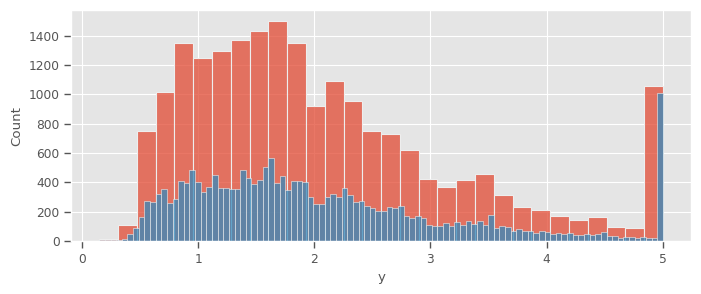

In [10]:
import seaborn

plt.style.use( style = 'ggplot' )
seaborn.set_context("paper") 

plt.figure( figsize = ( 8, 3 ) )
seaborn.histplot( df0['y'], bins = 30 )
seaborn.histplot( df0['y'], bins = 100 )

<Axes: xlabel='y'>

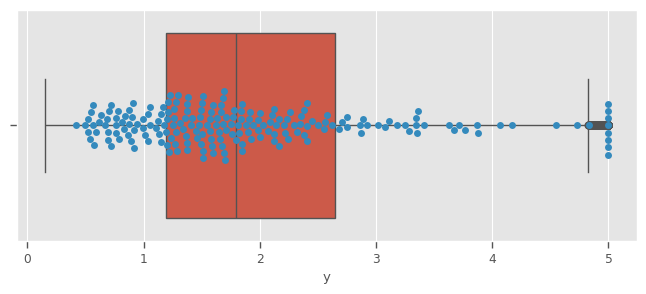

In [18]:
seaborn.set_context("paper") 
plt.figure( figsize = ( 8, 3 ) )
seaborn.boxplot(  df0['y'], orient = 'h' )
seaborn.swarmplot(  df0['y'].sample(200), orient = 'h' )

<Axes: ylabel='y'>

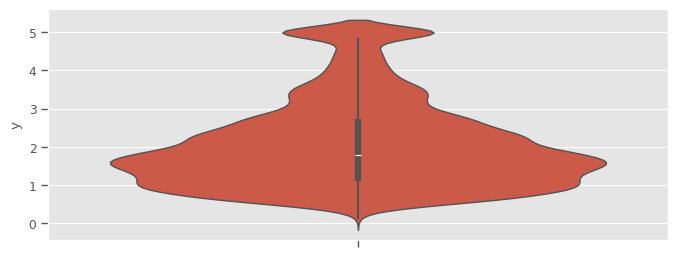

In [21]:
plt.figure( figsize = ( 8, 3 ) )
seaborn.violinplot(  df0['y'], orient = 'v' )

<Figure size 2000x2000 with 0 Axes>

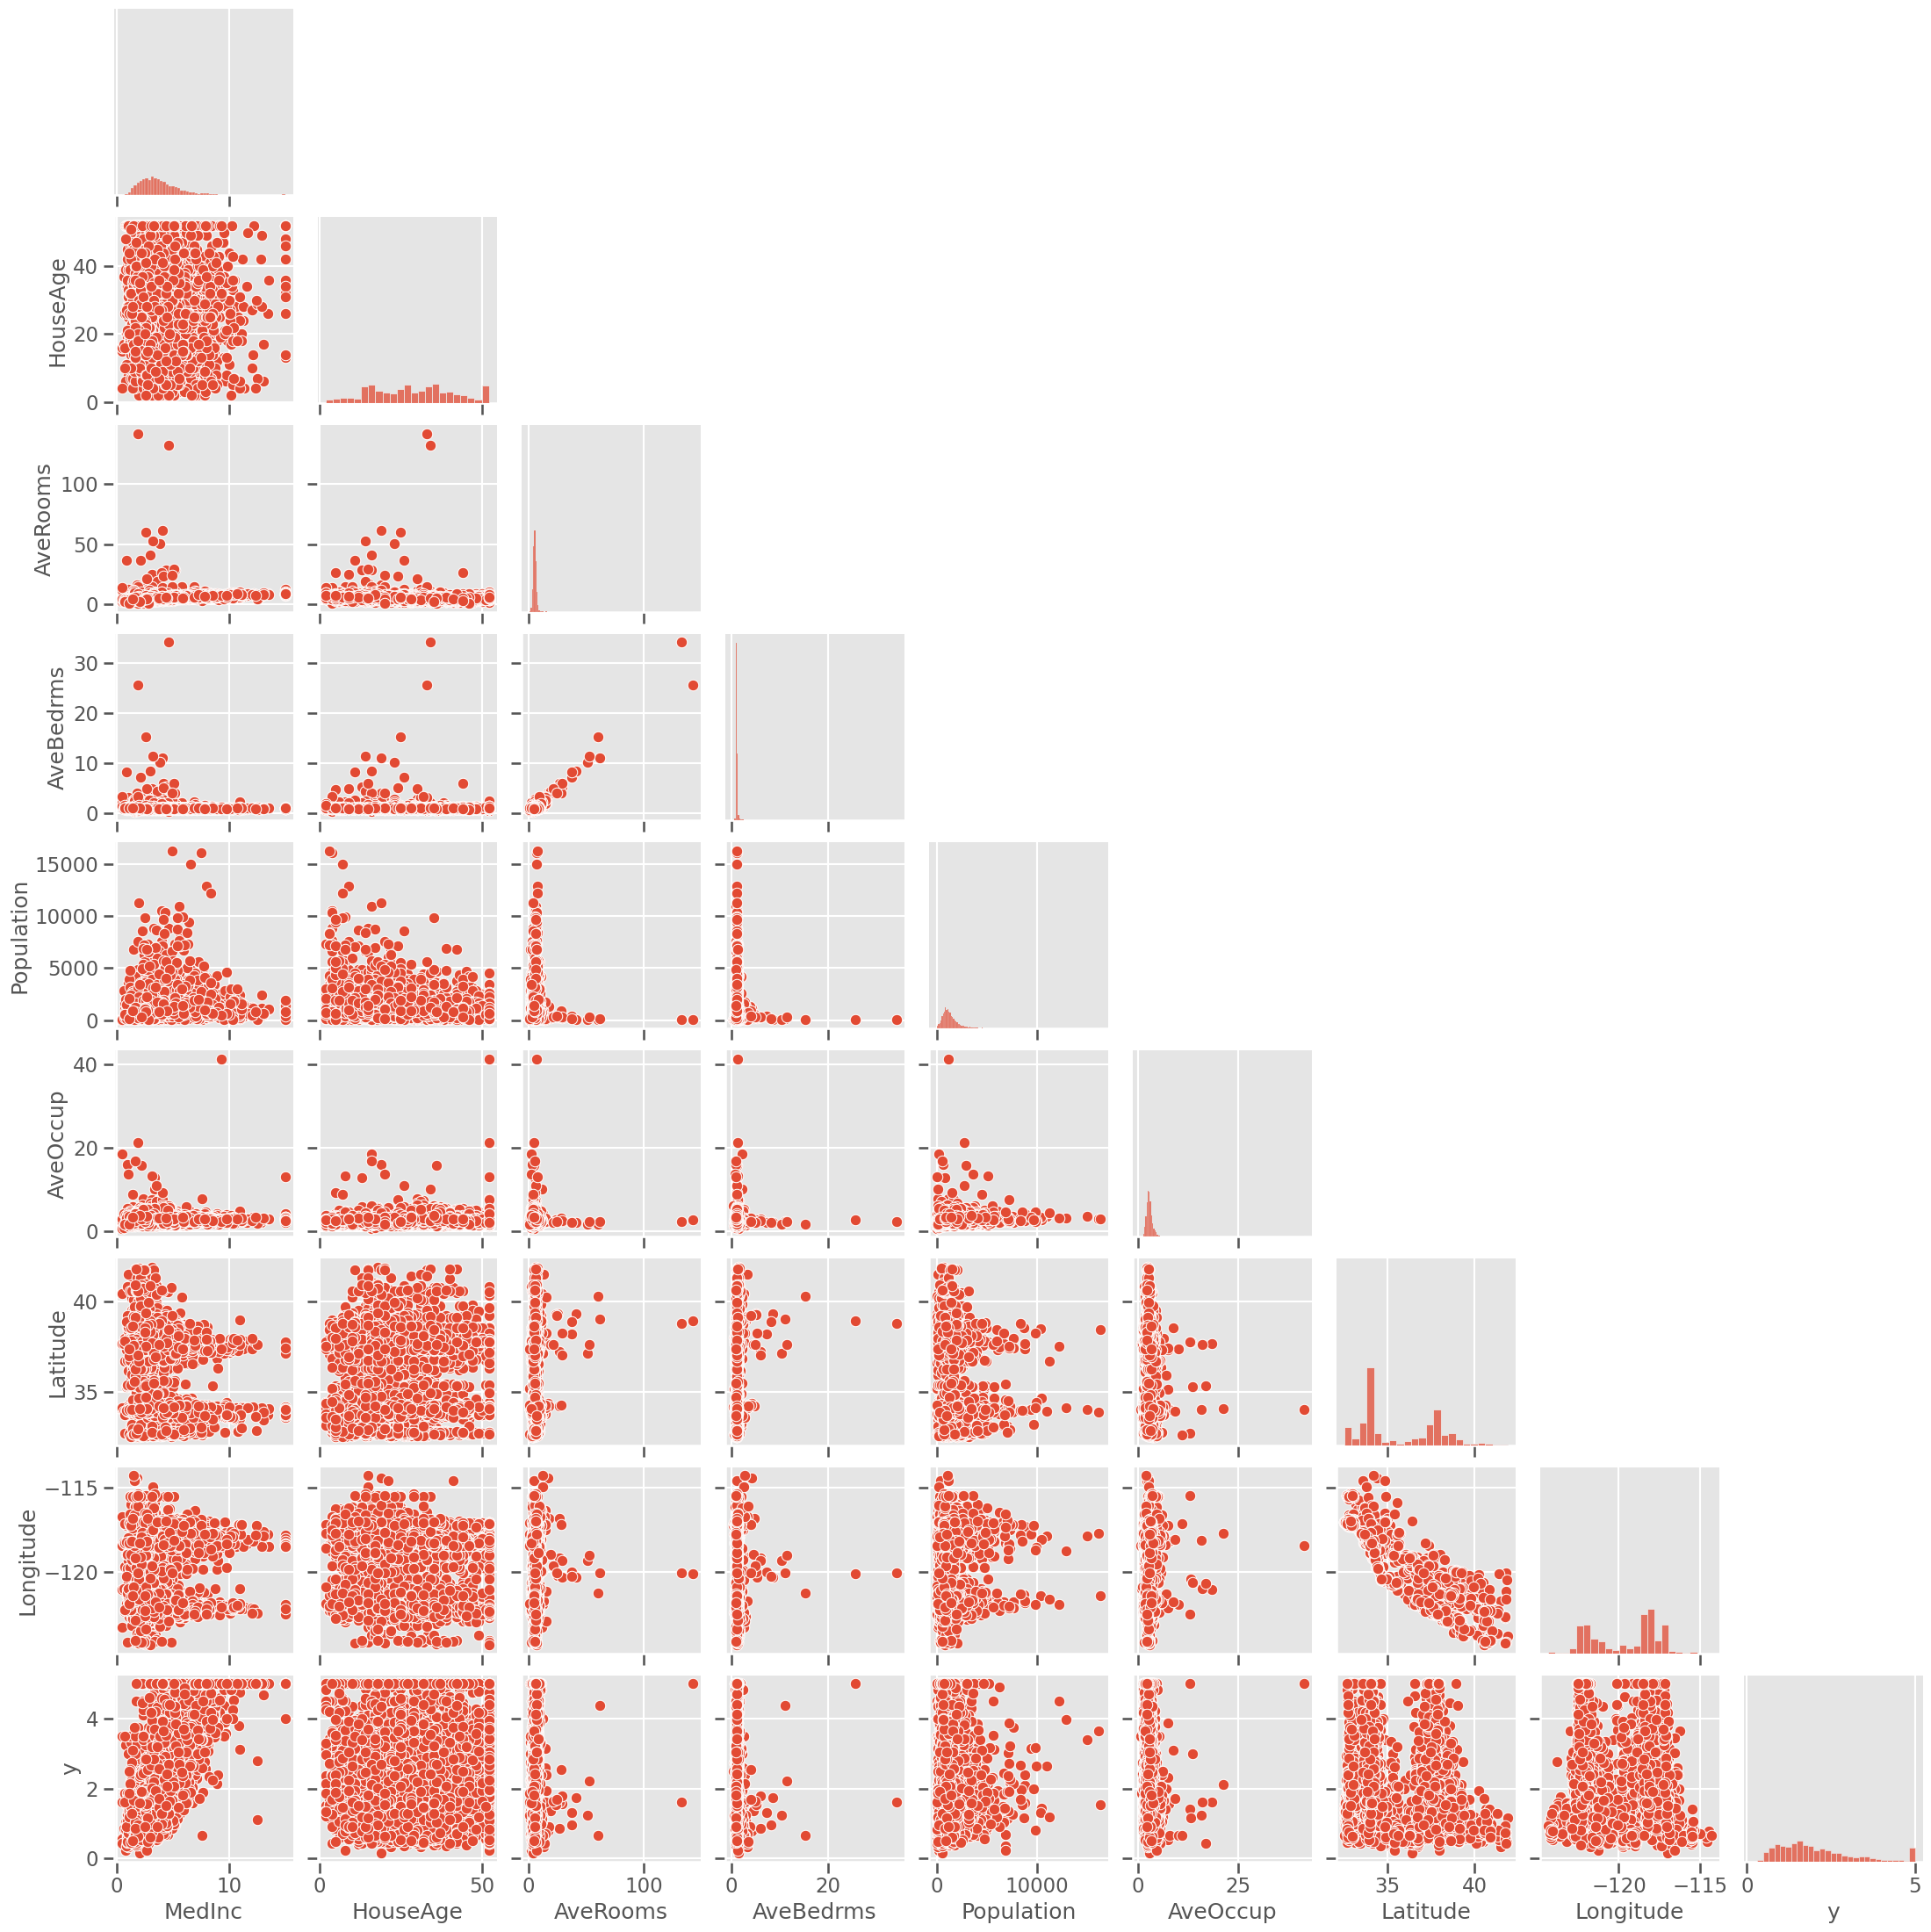

In [25]:
plt.figure( figsize = ( 20, 20 ) )
seaborn.set_context("talk")
seaborn.pairplot( df0.sample( 5000 ), corner = True  )

20413


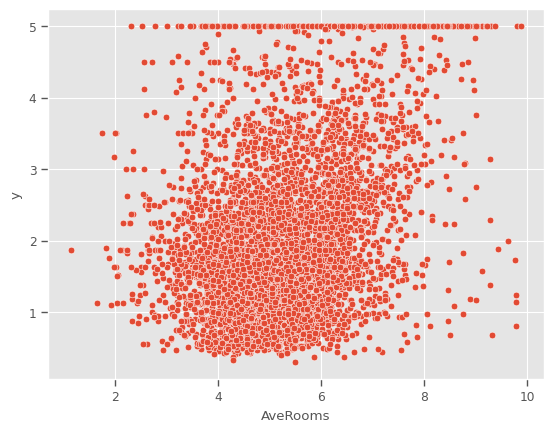

In [29]:
seaborn.set_context("paper")
df_small = df0[ df0['AveRooms'] < 10 ]
seaborn.scatterplot( x = 'AveRooms', y = 'y', data = df_small.sample( 5000 ) )
print( len(df_small) )

## Обучение лин. регр


In [21]:
from sklearn.model_selection import train_test_split

train, test = train_test_split( df0, test_size=0.2, random_state = 42 )

In [22]:
train

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,y
14196,3.2596,33.0,5.017657,1.006421,2300.0,3.691814,32.71,-117.03,1.030
8267,3.8125,49.0,4.473545,1.041005,1314.0,1.738095,33.77,-118.16,3.821
17445,4.1563,4.0,5.645833,0.985119,915.0,2.723214,34.66,-120.48,1.726
14265,1.9425,36.0,4.002817,1.033803,1418.0,3.994366,32.69,-117.11,0.934
2271,3.5542,43.0,6.268421,1.134211,874.0,2.300000,36.78,-119.80,0.965
...,...,...,...,...,...,...,...,...,...
11284,6.3700,35.0,6.129032,0.926267,658.0,3.032258,33.78,-117.96,2.292
11964,3.0500,33.0,6.868597,1.269488,1753.0,3.904232,34.02,-117.43,0.978
5390,2.9344,36.0,3.986717,1.079696,1756.0,3.332068,34.03,-118.38,2.221
860,5.7192,15.0,6.395349,1.067979,1777.0,3.178891,37.58,-121.96,2.835


In [23]:
test

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,y
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01,0.47700
3024,2.5313,30.0,5.039384,1.193493,1565.0,2.679795,35.14,-119.46,0.45800
15663,3.4801,52.0,3.977155,1.185877,1310.0,1.360332,37.80,-122.44,5.00001
20484,5.7376,17.0,6.163636,1.020202,1705.0,3.444444,34.28,-118.72,2.18600
9814,3.7250,34.0,5.492991,1.028037,1063.0,2.483645,36.62,-121.93,2.78000
...,...,...,...,...,...,...,...,...,...
15362,4.6050,16.0,7.002212,1.066372,1351.0,2.988938,33.36,-117.22,2.63300
16623,2.7266,28.0,6.131915,1.256738,1650.0,2.340426,35.36,-120.83,2.66800
18086,9.2298,25.0,7.237676,0.947183,1585.0,2.790493,37.31,-122.05,5.00001
2144,2.7850,36.0,5.289030,0.983122,1227.0,2.588608,36.77,-119.76,0.72300


In [5]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()


In [24]:
lin_reg.fit( train[ ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population','AveOccup','Latitude','Longitude'] ], train['y'] )

LinearRegression()

In [25]:
y_pred_train = lin_reg.predict( train[ ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population','AveOccup','Latitude','Longitude'] ] )
 
y_pred_test = lin_reg.predict( test[ ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population','AveOccup','Latitude','Longitude'] ] )

In [27]:
print( f"Train R2: {r2_score(train['y'], y_pred_train):.4f}")
print( f"Test R2:  {r2_score(test['y'], y_pred_test):.4f}")

Train R2: 0.6126
Test R2:  0.5758


In [13]:
MSE = ((y_pred - df0['y'].values)**2).mean()

In [14]:
MSE**.5

np.float64(0.7241001216576387)

In [ ]:
MAE = np.abs((y_pred - df0['y'].values)).mean()
MAE

np.float64(0.5311643817546476)

In [19]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [20]:
r2_score(df0['y'], y_pred)
# R2 = 1, предсказания идеальны, 
# R2 > 0.7 хорошие предсказания,
# R2 > 0.5 предсказания удовлетворительные, 
# R2 = 0, предсказания хуже, чем просто среднее значение, 
# R2 < 0, предсказания хуже, чем просто среднее значение

0.606232685199805